# Screening factor across the (radius, density) plane

The screening factor $S \equiv |y'| / |y'_{\rm lin}|$ measures the field gradient against its unscreened linear value: $S \to 1$ is unscreened, $S \to 0$ fully screened.

Three radii organise the picture, and all three are marked:

- $x_s$ — edge of the Chameleon core, inside which the field is pinned at its interior minimum
- $x_{\rm V+Ch}$ — the symbiotic Vainshtein radius
- $x_{\rm V}$ — the pure-Galileon Vainshtein radius, which the symbiotic one always sits inside

The pure-Galileon baseline is **shift-symmetric**: it carries no conformal coupling, so its kinetic coefficient is $\epsilon$ rather than $\epsilon\tilde\alpha$.

The sweep is 106 densities and is cached to `composite_data.npz`.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))
sys.path.insert(0, os.path.abspath(os.path.join('..', '..', 'main')))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D

import styling
import mixed_screening as ms
import composite_sweep as sweep

styling.apply()
AN = styling.ANNOT

In [2]:
A, A_PURE, BETA = sweep.A, sweep.A_PURE, sweep.BETA
BG, EPS_EDGE, DC0 = sweep.BG, sweep.EPS_EDGE, sweep.DC_SLICE

lamC = ms.compton_wavelength(A, BG)          # background Chameleon range
print(f'A = {A},  pure-Galileon A = {A_PURE},  beta = {BETA}')
print(f'rho_bg = {BG},  slice at rho_in = {DC0:.0f},  lambda_bg = {lamC:.1f}')

A = 1.9600000000000002,  pure-Galileon A = 1.0,  beta = 50.0
rho_bg = 0.0003,  slice at rho_in = 7000,  lambda_bg = 434.3


## The sweep

Each density is warm-started from the previous; a cold solve stalls in the mid-density range.

In [3]:
if os.path.exists(sweep.OUT):
    d = np.load(sweep.OUT)
    print('loaded cached sweep')
else:
    print('computing sweep (106 densities, ~1 minute)...')
    sweep.run()
    d = np.load(sweep.OUT)

M, xvs, xvp, xs = d['M'], d['xvs'], d['xvp'], d['xs']
dcs, xg, ok = d['dcs'], d['xg'], d['okmask']
print(f'{ok.sum()}/{len(ok)} densities converged;  cores found for {np.isfinite(xs).sum()}')

# the core edge must lie inside the source; flag it rather than silently plotting it
if np.any(xs[np.isfinite(xs)] >= 1.0):
    print('WARNING: x_s >= 1 at', dcs[np.isfinite(xs) & (xs >= 1.0)])

loaded cached sweep
106/106 densities converged;  cores found for 45


## The 1D slice

At a single density, comparing all three theories on the same source: pure Vainshtein (analytic, sourced by the mass perturbation), pure Chameleon ($\beta = 0$), and the symbiotic solution.

In [4]:
xf = np.logspace(-1, np.log10(4000), 700)

Im = ms.mass_charge(xf, DC0, BG, EPS_EDGE)            # mass-perturbation charge
yp_lin = np.abs(Im) / (A * xf**2)                     # unscreened reference gradient

S_pureV = np.abs(ms.gradient(xf, Im, A, BETA)) / yp_lin

s_cham = ms.solve(A=A, beta=0.0, rho_in=DC0, rho_bg=BG, eps_edge=EPS_EDGE,
                  x_init=sweep.XI, tol=1e-3, max_nodes=2_000_000)
S_cham = np.abs(s_cham.sol(xf)[1]) / yp_lin

s_sym = ms.solve(A=A, beta=BETA, rho_in=DC0, rho_bg=BG, eps_edge=EPS_EDGE,
                 x_init=sweep.XI, tol=1e-3, max_nodes=2_000_000)
S_sym = np.abs(s_sym.sol(xf)[1]) / yp_lin

xs0 = ms.core_radius(s_sym, DC0)
xV0 = ms.vainshtein_radius(xf, ms.solved_charge(s_sym, xf), A, BETA)
print(f'converged: chameleon={s_cham.success}  symbiotic={s_sym.success}')
print(f'x_s = {xs0:.3f},  x_V+Ch = {xV0:.2f},  x_V(pure) = '
      f'{ms.vainshtein_radius_analytic(A_PURE, BETA, DC0, BG):.2f}')

converged: chameleon=True  symbiotic=True
x_s = 0.606,  x_V+Ch = 56.89,  x_V(pure) = 97.73


## Figure

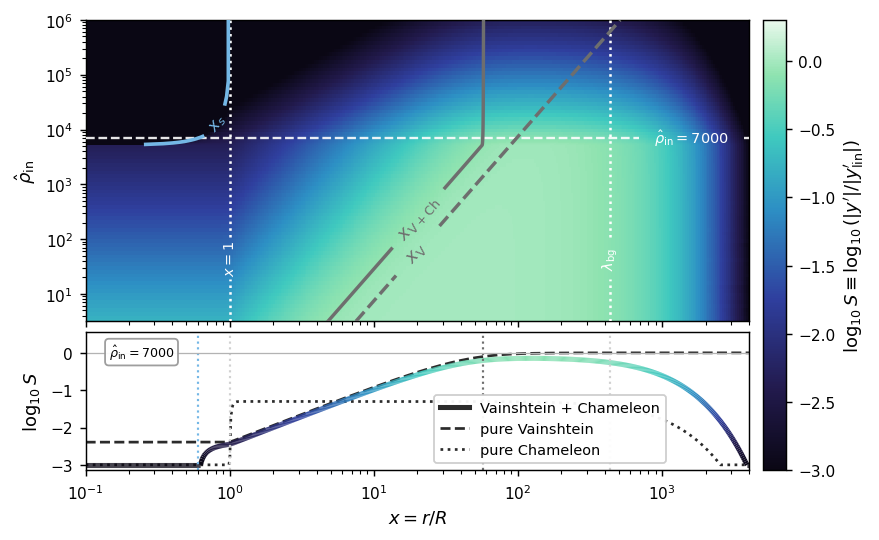

In [5]:
# Line style separates the theories, so the curves only need to be legible.
# Which neutral depends on the ground: the map is dark, the lower panel white.
C_MAP = styling.LINE['secondary']      # curves over the map
C_PANEL = styling.LINE['primary']      # curves over the white lower panel
C_REF = '0.82'                         # lower-panel reference verticals
C_VCH = C_V = C_MAP
C_XS = '#74b7e6'                       # lighter blue, to read against the dark map
cmap = styling.sequential().copy(); cmap.set_bad('0.75')
norm = Normalize(vmin=-3, vmax=0.3)

fig = plt.figure(figsize=(styling.WIDE, 4.5))
gs = GridSpec(2, 1, height_ratios=[2.4, 1.1], hspace=0.05, figure=fig)
ax = fig.add_subplot(gs[0]); axb = fig.add_subplot(gs[1], sharex=ax)
ax.set_facecolor('0.75')

im = ax.pcolormesh(xg, dcs, np.log10(np.clip(np.ma.masked_invalid(M), 1e-3, 2)),
                   cmap=cmap, shading='auto', norm=norm)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(0.1, 4000); ax.set_ylim(dcs[0], dcs[-1])
ax.set_ylabel(r'$\hat\rho_{\rm in}$')
plt.setp(ax.get_xticklabels(), visible=False)
cb = fig.colorbar(im, ax=[ax, axb], fraction=0.046, pad=0.02)
cb.set_label(r'$\log_{10} S \equiv \log_{10}(|y^\prime|/|y^\prime_\mathrm{lin}|)$')
fig.canvas.draw()

def curve(xarr, yarr, color, y0, txt, ls='-', lw=1.9, dy=0.14, fsz=AN):
    """Draw a radius curve with its label inline, in a break in the line."""
    xx, yy = np.asarray(xarr, float), np.asarray(yarr, float)
    ok = np.isfinite(xx) & np.isfinite(yy)
    xg2 = xx.copy()
    xg2[np.abs(np.log10(np.where(yy > 0, yy, np.nan)) - np.log10(y0)) < dy] = np.nan
    ax.plot(xg2, yy, color=color, ls=ls, lw=lw, zorder=5)
    idx = np.where(ok)[0]
    i = idx[int(np.argmin(np.abs(np.log10(yy[idx]) - np.log10(y0))))]
    j0, j1 = max(i - 4, idx[0]), min(i + 4, idx[-1])
    p1 = ax.transData.transform((xx[j0], yy[j0])); p2 = ax.transData.transform((xx[j1], yy[j1]))
    rot = np.degrees(np.arctan2(p2[1] - p1[1], p2[0] - p1[0]))
    ax.text(xx[i], yy[i], txt, color=color, fontsize=fsz, ha='center', va='center',
            rotation=rot, rotation_mode='anchor', zorder=6)

def vline(xc, color, y0, txt, ls=':', lw=1.4, dy=0.16, fsz=AN):
    yy = dcs.astype(float); xx = np.full_like(yy, xc)
    xx[np.abs(np.log10(yy) - np.log10(y0)) < dy] = np.nan
    ax.plot(xx, yy, color=color, ls=ls, lw=lw, zorder=3)
    ax.text(xc, y0, txt, color=color, fontsize=fsz, ha='center', va='center',
            rotation=90, zorder=6)

def hline(yc, color, x0, txt, ls='--', lw=1.3, dx=0.20, fsz=AN, alpha=0.9):
    xa = np.logspace(-1, np.log10(4000), 400); yy = np.full_like(xa, yc)
    xg3 = xa.copy(); xg3[np.abs(np.log10(xa) - np.log10(x0)) < dx] = np.nan
    ax.plot(xg3, yy, color=color, ls=ls, lw=lw, alpha=alpha, zorder=3)
    ax.text(x0, yc, txt, color=color, fontsize=fsz, ha='center', va='center', zorder=6)

curve(xvs, dcs, C_VCH, 240., r'$x_{\rm V+Ch}$', ls='-',  lw=1.9, dy=0.55, fsz=AN + 2)
curve(xvp, dcs, C_V,    60., r'$x_{\rm V}$',    ls='--', lw=1.9, dy=0.44, fsz=AN + 2)
curve(xs,  dcs, C_XS, 1.4e4, r'$x_s$',          ls='-',  lw=2.0, dy=0.26, fsz=AN + 1)
vline(1.0,  'w', 45., r'$x=1$', dy=0.36)
vline(lamC, 'w', 45., r'$\lambda_{\rm bg}$', dy=0.36)
hline(DC0,  'w', 1600., rf'$\hat\rho_{{\rm in}}={DC0:.0f}$', dx=0.36, fsz=AN)

# ---- lower panel: the three theories at one density ----
lS = np.log10(np.clip(S_sym, 1e-3, 2))
axb.plot(xf, np.log10(np.clip(S_pureV, 1e-3, 2)), color=C_PANEL, lw=1.5, ls='--')
axb.plot(xf, np.log10(np.clip(S_cham,  1e-3, 2)), color=C_PANEL, lw=1.5, ls=':')
pts = np.array([xf, lS]).T.reshape(-1, 1, 2)
segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
lc = LineCollection(segs, cmap=cmap, norm=norm)      # coloured by its own S value
lc.set_array(lS[:-1]); lc.set_linewidth(2.8); axb.add_collection(lc)

for xc, cc in [(xs0, C_XS), (1.0, C_REF), (xV0, C_MAP), (lamC, C_REF)]:
    if np.isfinite(xc):
        axb.axvline(xc, color=cc, ls=':', lw=1.2)
axb.axhline(0, color='0.7', lw=0.7, ls='-')
axb.set_xscale('log'); axb.set_xlim(0.1, 4000); axb.set_ylim(-3.15, 0.55)
axb.set_xlabel(r'$x = r/R$'); axb.set_ylabel(r'$\log_{10}S$')
axb.legend(handles=[Line2D([], [], color=C_PANEL, lw=2.8, label='Vainshtein + Chameleon'),
                    Line2D([], [], color=C_PANEL, lw=1.5, ls='--', label='pure Vainshtein'),
                    Line2D([], [], color=C_PANEL, lw=1.5, ls=':', label='pure Chameleon')],
           loc='lower center', bbox_to_anchor=(0.70, 0.0), framealpha=0.95)
axb.text(0.145, 0.02, rf'$\hat\rho_{{\rm in}}={DC0:.0f}$', fontsize=AN - 1, color='k',
         va='center', bbox=dict(boxstyle='round', fc='white', ec='0.6', alpha=0.95))

fig.savefig('composite.png')
plt.show()